In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn import tree, metrics, model_selection, preprocessing

In [2]:
df = pd.read_csv('Video_Games_Sales_as_at_22_Dec_2016.csv')
df

,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16714,Samurai Warriors: Sanada Maru,PS3,2016.0,Action,Tecmo Koei,0.00,0.00,0.01,0.00,0.01,NaN,NaN,NaN,NaN,NaN,NaN
16715,LMA Manager 2007,X360,2006.0,Sports,Codemasters,0.00,0.01,0.00,0.00,0.01,NaN,NaN,NaN,NaN,NaN,NaN
16716,Haitaka no Psychedelica,PSV,2016.0,Adventure,Idea Factory,0.00,0.00,0.01,0.00,0.01,NaN,NaN,NaN,NaN,NaN,NaN
16717,Spirits & Spells,GBA,2003.0,Platform,Wanadoo,0.01,0.00,0.00,0.00,0.01,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
missing = df[df['Critic_Score'].isna()]
has_score = df[df['Critic_Score'].notna()]

# Japan-only = sold in Japan, sold nothing in NA
jp_only = (df['JP_Sales'] > 0) & (df['NA_Sales'] == 0)
NA_only = (df['NA_Sales'] > 0) & (df['JP_Sales'] == 0)

print("Japan-only share among games missing a score:", jp_only[missing.index].mean())
print("Japan-only share among games with a score:", jp_only[has_score.index].mean())
print("Japan-only games that have a score:", jp_only[has_score.index].sum(), "of", jp_only.sum())
print("NA-only games that have a score:", NA_only[has_score.index].sum(), "of", NA_only.sum())

Japan-only share among games missing a score: 0.3898858075040783
Japan-only share among games with a score: 0.01745114907213961
Japan-only games that have a score: 142 of 3488
NA-only games that have a score: 5554 of 9492


We can see that many Japan-only games have no critic scores, so dropping rows with a missing critic score would remove Japan games at a much higher rate than NA-only games. Instead of dropping those rows, I keep every game and fill missing critic scores with -1. Real critic scores run from 0 to 100, so -1 lets the decision tree treat "no critic score" as its own case. I only drop rows missing 'Platform', 'Genre', or 'Year_of_Release'.

In [4]:
df = df.dropna(subset=['Platform', 'Genre', 'Year_of_Release'])
df['critic_filled'] = df.Critic_Score.fillna(-1)
print('Share missing critic score:', (df.critic_filled == -1).mean())
df

Share missing critic score: 0.5146522373540856


,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating,critic_filled
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8,322.0,Nintendo,E,76.0
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN,-1.0
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E,82.0
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8,192.0,Nintendo,E,80.0
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN,-1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16714,Samurai Warriors: Sanada Maru,PS3,2016.0,Action,Tecmo Koei,0.00,0.00,0.01,0.00,0.01,NaN,NaN,NaN,NaN,NaN,NaN,-1.0
16715,LMA Manager 2007,X360,2006.0,Sports,Codemasters,0.00,0.01,0.00,0.00,0.01,NaN,NaN,NaN,NaN,NaN,NaN,-1.0
16716,Haitaka no Psychedelica,PSV,2016.0,Adventure,Idea Factory,0.00,0.00,0.01,0.00,0.01,NaN,NaN,NaN,NaN,NaN,NaN,-1.0
16717,Spirits & Spells,GBA,2003.0,Platform,Wanadoo,0.01,0.00,0.00,0.00,0.01,NaN,NaN,NaN,NaN,NaN,NaN,-1.0


In [5]:
encoder = preprocessing.OneHotEncoder(sparse_output=False, handle_unknown='ignore')
encoded = encoder.fit_transform(df[['Platform', 'Genre']])
encoded_df = pd.DataFrame(encoded, columns=encoder.get_feature_names_out(), index=df.index)
df = pd.concat([df, encoded_df], axis=1)

platform_cols = []
genre_cols = []
for column in df.columns:
    if column.startswith('Platform_'):
        platform_cols.append(column)
    elif column.startswith('Genre_'):
        genre_cols.append(column)
year_cols = ['Year_of_Release']
critic_cols = ['critic_filled']

features = platform_cols + genre_cols + year_cols + critic_cols
print(len(df), len(features))

16448 45


In [6]:
na_cut = df.NA_Sales.quantile(0.9)
jp_cut = df.JP_Sales.quantile(0.9)
df['na_hit'] = (df.NA_Sales >= na_cut).astype(int)
df['jp_hit'] = (df.JP_Sales >= jp_cut).astype(int)

print('NA cutoff:', na_cut, 'JP cutoff:', jp_cut)
print(df.na_hit.value_counts())
print(df.jp_hit.value_counts())

NA cutoff: 0.61 JP cutoff: 0.18
na_hit
0    14783
1     1665
Name: count, dtype: int64
jp_hit
0    14789
1     1659
Name: count, dtype: int64


In [7]:
df['strat'] = df.na_hit.astype(str) + '_' + df.jp_hit.astype(str)
train_df, test_df = model_selection.train_test_split(
    df, test_size=0.2, stratify=df.strat, random_state=42
)
print(len(train_df), len(test_df))

13158 3290


In [8]:
xval = model_selection.KFold(10, shuffle=True, random_state=42)
scorer = metrics.make_scorer(metrics.cohen_kappa_score)
grid = {'max_depth': [4, 6, 8, 10, 12, 15, 20], 'min_samples_leaf': [2]}

depth_table = pd.DataFrame()
for label in ['na_hit', 'jp_hit']:
    model = tree.DecisionTreeClassifier(class_weight='balanced', random_state=42)
    gridsearch = model_selection.GridSearchCV(model, grid, scoring=scorer, cv=xval)
    gridsearch.fit(train_df[features], train_df[label])
    results_df = pd.DataFrame(gridsearch.cv_results_)
    depth_table[label] = results_df['mean_test_score'].values

depth_table.index = grid['max_depth']
print(depth_table)

      na_hit    jp_hit
4   0.223768  0.274070
6   0.219304  0.260033
8   0.231350  0.279077
10  0.241247  0.282775
12  0.250322  0.285285
15  0.249024  0.262528
20  0.240498  0.262275


In [9]:
DEPTH = 12  # shared depth chosen from the table above

final_models = {}
for label in ['na_hit', 'jp_hit']:
    model = tree.DecisionTreeClassifier(max_depth=DEPTH, min_samples_leaf=2,
                                        class_weight='balanced', random_state=42)
    model.fit(train_df[features], train_df[label])
    preds = model.predict(test_df[features])
    final_models[label] = model

    print(label)
    print('  Precision:', metrics.precision_score(test_df[label], preds))
    print('  Recall:   ', metrics.recall_score(test_df[label], preds))
    print('  Kappa:    ', metrics.cohen_kappa_score(test_df[label], preds))
    print(metrics.confusion_matrix(test_df[label], preds))

na_hit
  Precision: 0.23283261802575106
  Recall:    0.6516516516516516
  Kappa:     0.22793463570185624
[[2242  715]
 [ 116  217]]
jp_hit
  Precision: 0.2437641723356009
  Recall:    0.6475903614457831
  Kappa:     0.24323702650970602
[[2291  667]
 [ 117  215]]


In [10]:
importance_table = pd.DataFrame()
for label in ['na_hit', 'jp_hit']:
    model = final_models[label]
    importances = pd.Series(model.feature_importances_, index=features)
    importance_table[label] = [
        importances[platform_cols].sum(),
        importances[genre_cols].sum(),
        importances[year_cols].sum(),
        importances[critic_cols].sum(),
    ]

importance_table.index = ['Platform', 'Genre', 'Year', 'Critic Score']
print(importance_table)

                na_hit    jp_hit
Platform      0.187932  0.269827
Genre         0.147101  0.229706
Year          0.245761  0.364944
Critic Score  0.419206  0.135523


In [11]:
feature_sets = {
    'All features': features,
    'No Platform': genre_cols + year_cols + critic_cols,
    'No Genre': platform_cols + year_cols + critic_cols,
    'No Year': platform_cols + genre_cols + critic_cols,
    'No Critic': platform_cols + genre_cols + year_cols,
    'Critic only': critic_cols,
}

rows = []
for label in ['na_hit', 'jp_hit']:
    for set_name, cols in feature_sets.items():
        model = tree.DecisionTreeClassifier(max_depth=DEPTH, min_samples_leaf=2,
                                            class_weight='balanced', random_state=42)
        model.fit(train_df[cols], train_df[label])
        preds = model.predict(test_df[cols])
        rows.append({
            'region': label,
            'features': set_name,
            'precision': metrics.precision_score(test_df[label], preds),
            'recall': metrics.recall_score(test_df[label], preds),
            'kappa': metrics.cohen_kappa_score(test_df[label], preds),
        })

ablation_df = pd.DataFrame(rows)
print(ablation_df)

    region      features  precision    recall     kappa
0   na_hit  All features   0.232833  0.651652  0.227935
1   na_hit   No Platform   0.217306  0.663664  0.206382
2   na_hit      No Genre   0.244848  0.606607  0.239148
3   na_hit       No Year   0.280775  0.609610  0.285433
4   na_hit     No Critic   0.138637  0.873874  0.078270
5   na_hit   Critic only   0.227994  0.474474  0.198388
6   jp_hit  All features   0.243764  0.647590  0.243237
7   jp_hit   No Platform   0.249027  0.578313  0.241076
8   jp_hit      No Genre   0.204819  0.716867  0.191730
9   jp_hit       No Year   0.272857  0.575301  0.270256
10  jp_hit     No Critic   0.295312  0.569277  0.295234
11  jp_hit   Critic only   0.134684  0.801205  0.069901


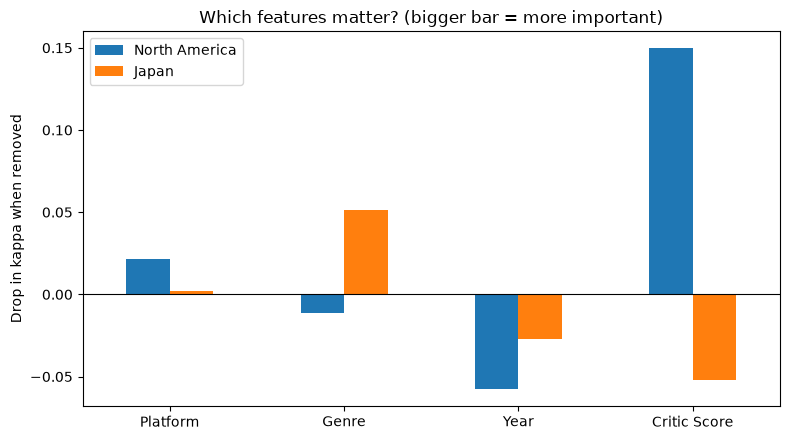

In [12]:
drops = pd.DataFrame()
for label in ['na_hit', 'jp_hit']:
    region = ablation_df[ablation_df.region == label].set_index('features')
    full = region.loc['All features', 'kappa']
    drops[label] = full - region.loc[['No Platform', 'No Genre', 'No Year', 'No Critic'], 'kappa']

drops.index = ['Platform', 'Genre', 'Year', 'Critic Score']
drops.columns = ['North America', 'Japan']

ax = drops.plot(kind='bar', figsize=(8, 4.5), rot=0)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('Drop in kappa when removed')
ax.set_title('Which features matter? (bigger bar = more important)')
plt.tight_layout()
plt.savefig('feature_drop_chart.png', dpi=200)
plt.show()

Check: is it the critic score itself that matters, or just whether a game has one? A model that only knows "has a critic score or not" is compared to one that knows the actual score.

In [13]:
train_df = train_df.copy()
test_df = test_df.copy()
train_df['has_critic'] = (train_df.critic_filled != -1).astype(int)
test_df['has_critic'] = (test_df.critic_filled != -1).astype(int)

for label in ['na_hit', 'jp_hit']:
    model = tree.DecisionTreeClassifier(max_depth=DEPTH, min_samples_leaf=2,
                                        class_weight='balanced', random_state=42)
    model.fit(train_df[['has_critic']], train_df[label])
    preds = model.predict(test_df[['has_critic']])
    print(label, 'Has-score-only kappa:', metrics.cohen_kappa_score(test_df[label], preds))

na_hit Has-score-only kappa: 0.0666058335211408
jp_hit Has-score-only kappa: 0.07956010825404747


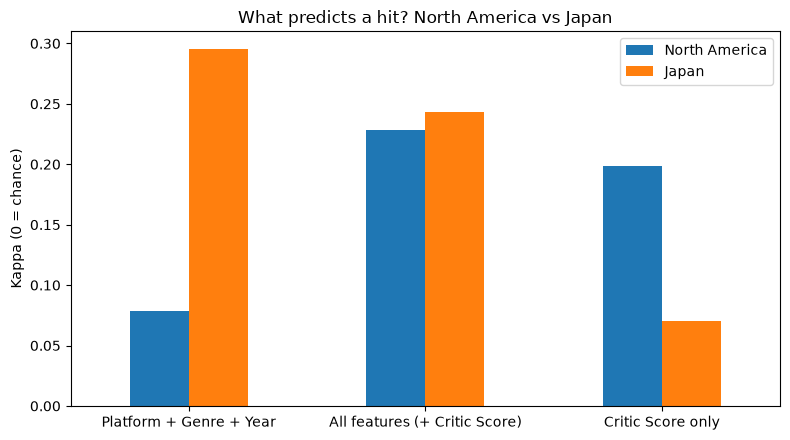

In [14]:
summary = pd.DataFrame({
    'North America': [
        ablation_df.query("region == 'na_hit' and features == 'No Critic'").kappa.iloc[0],
        ablation_df.query("region == 'na_hit' and features == 'All features'").kappa.iloc[0],
        ablation_df.query("region == 'na_hit' and features == 'Critic only'").kappa.iloc[0],
    ],
    'Japan': [
        ablation_df.query("region == 'jp_hit' and features == 'No Critic'").kappa.iloc[0],
        ablation_df.query("region == 'jp_hit' and features == 'All features'").kappa.iloc[0],
        ablation_df.query("region == 'jp_hit' and features == 'Critic only'").kappa.iloc[0],
    ],
}, index=['Platform + Genre + Year', 'All features (+ Critic Score)', 'Critic Score only'])

ax = summary.plot(kind='bar', figsize=(8, 4.5), rot=0)
ax.set_ylabel('Kappa (0 = chance)')
ax.set_title('What predicts a hit? North America vs Japan')
plt.tight_layout()
plt.savefig('summary_chart.png', dpi=200)
plt.show()